<a href="https://colab.research.google.com/github/sabakrish/Data-Science-Teaching/blob/main/Student_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../content/sample_data/Data_student_performance_analysis/student_performance_synthetic.csv")
df.head()



,student_id,weekly_study_hours,attendance_percent,prior_assessment_score,final_score,study_time_category
0,1,2,56,82,60.0,Low
1,2,2,98,82,75.0,Low
2,3,9,60,72,73.5,High
3,4,4,69,67,64.0,Moderate
4,5,10,56,70,79.0,High


In [2]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("data_type"))
display(df.isna().sum().to_frame("missing_values"))
display(df.describe().T)



Shape: (200, 6)


,data_type
student_id,int64
weekly_study_hours,int64
attendance_percent,int64
prior_assessment_score,int64
final_score,float64
study_time_category,object


,missing_values
student_id,0
weekly_study_hours,0
attendance_percent,0
prior_assessment_score,0
final_score,0
study_time_category,0


,count,mean,std,min,25%,50%,75%,max
student_id,200.0,100.500,57.879185,1.0,50.750,100.5,150.250,200.0
weekly_study_hours,200.0,5.415,2.805733,1.0,3.000,5.0,8.000,10.0
attendance_percent,200.0,78.080,13.893117,55.0,65.750,78.0,91.000,100.0
prior_assessment_score,200.0,66.930,17.688684,35.0,52.000,68.0,82.000,95.0
final_score,200.0,69.502,11.389363,37.8,61.375,70.1,77.375,93.3


In [3]:
assert df["attendance_percent"].between(0, 100).all()
assert df["prior_assessment_score"].between(0, 100).all()
assert df["final_score"].between(0, 100).all()
print("Range checks passed.")


Range checks passed.


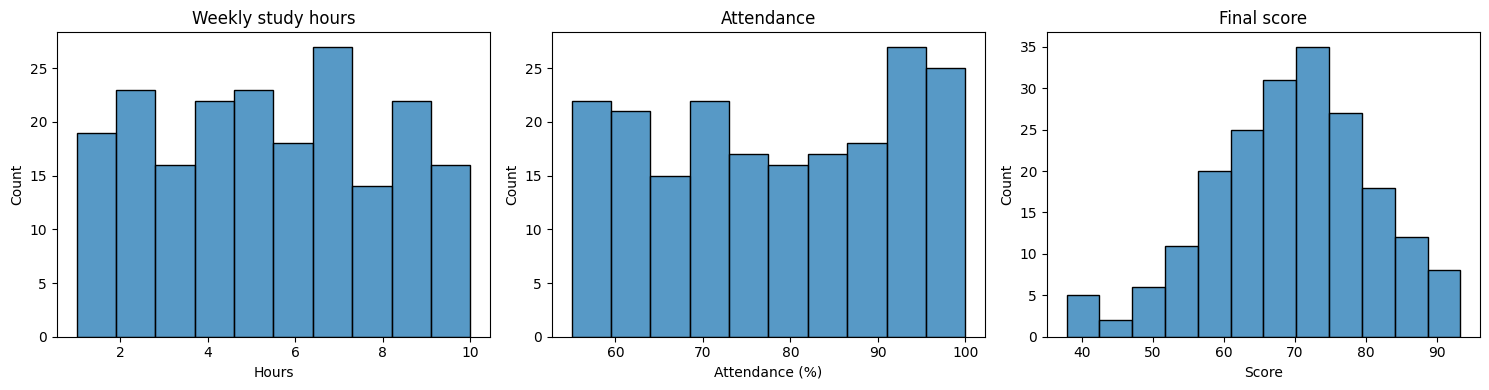

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["weekly_study_hours"], bins=10, ax=axes[0])
axes[0].set(title="Weekly study hours", xlabel="Hours")
sns.histplot(df["attendance_percent"], bins=10, ax=axes[1])
axes[1].set(title="Attendance", xlabel="Attendance (%)")
sns.histplot(df["final_score"], bins=12, ax=axes[2])
axes[2].set(title="Final score", xlabel="Score")
plt.tight_layout()
plt.show()

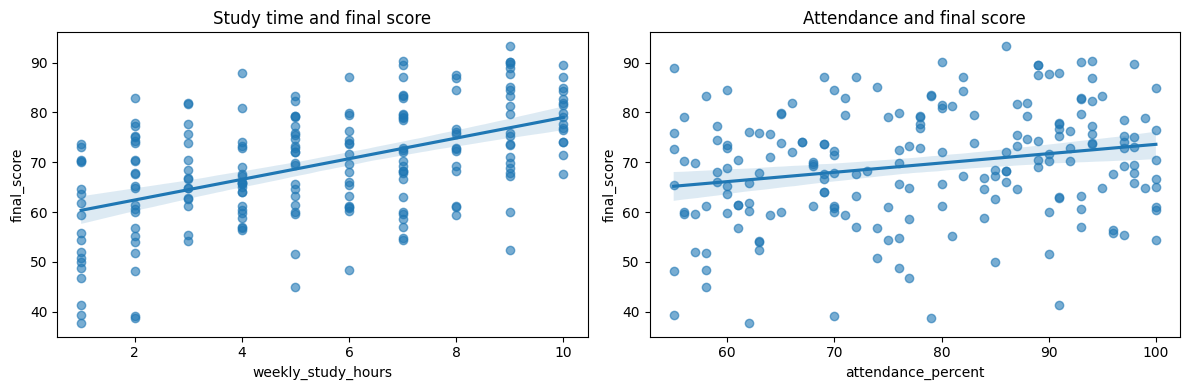

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=df, x="weekly_study_hours", y="final_score", ax=axes[0],
            scatter_kws={"alpha": 0.6})
axes[0].set_title("Study time and final score")
sns.regplot(data=df, x="attendance_percent", y="final_score", ax=axes[1],
            scatter_kws={"alpha": 0.6})
axes[1].set_title("Attendance and final score")
plt.tight_layout()
plt.show()

,weekly_study_hours,attendance_percent,prior_assessment_score,final_score
weekly_study_hours,1.00,0.00,-0.13,0.51
attendance_percent,0.00,1.00,-0.08,0.23
prior_assessment_score,-0.13,-0.08,1.00,0.47
final_score,0.51,0.23,0.47,1.00


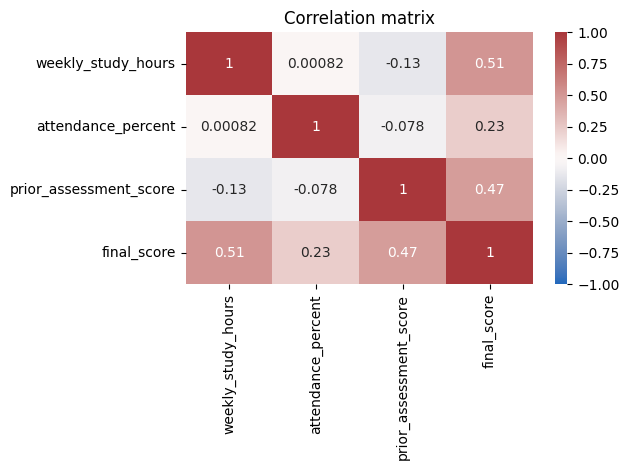

In [6]:
cols = ["weekly_study_hours", "attendance_percent", "prior_assessment_score", "final_score"]
corr = df[cols].corr()
display(corr.round(2))
sns.heatmap(corr, annot=True, cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()


In [7]:
group_summary = (
    df.groupby("study_time_category", observed=True)["final_score"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)
display(group_summary)


,count,mean,median,std
study_time_category,,,,
High,52,76.98,76.50,9.24
Low,58,62.79,64.70,11.66
Moderate,90,69.51,69.15,9.59
